# HW6 — Tayko: Predicting Spending

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

df = pd.read_csv("Tayko.csv")
d = df[df["Purchase"] == 1].copy()          # study only the purchasers

PRED1 = ["Freq", "last_update_days_ago", "Web order", "Gender=male", "US", "Address_is_res"]
PRED2 = ["Freq", "last_update_days_ago", "Address_is_res"]


def ols(X, y):
    """Least-squares fit with intercept -> table of coef / std_err / t / p_value."""
    A = np.c_[np.ones(len(X)), X.to_numpy(float)]
    beta = np.linalg.lstsq(A, y, rcond=None)[0]
    resid = y - A @ beta
    dof = len(y) - A.shape[1]
    se = np.sqrt(np.diag(resid @ resid / dof * np.linalg.inv(A.T @ A)))
    t = beta / se
    tab = pd.DataFrame({"coef": beta, "std_err": se, "t": t,
                        "p_value": 2 * stats.t.sf(abs(t), dof)},
                       index=["(Intercept)", *X.columns])
    tab.attrs["r2"] = 1 - resid @ resid / ((y - y.mean()) ** 2).sum()
    return tab


def predict(tab, X):
    return tab["coef"].iloc[0] + X.to_numpy(float) @ tab["coef"].iloc[1:].to_numpy()


def equation(tab, name):
    terms = "".join(f" {'+' if c >= 0 else '-'} {abs(c):.4g} * {v}"
                    for v, c in tab["coef"].iloc[1:].items())
    return f"{name}: Spending = {tab['coef'].iloc[0]:.4g}{terms}"


print(f"purchasers: {len(d)}")

purchasers: 1000


## (a) Spending vs Freq / Last_update

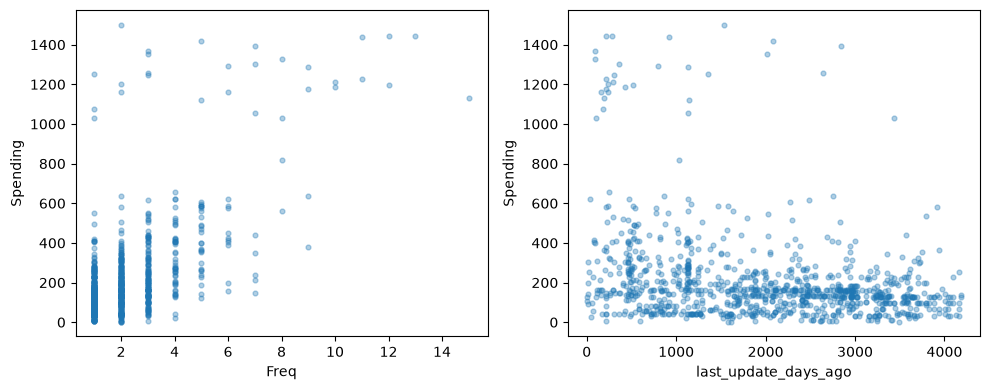

Freq                    0.645
last_update_days_ago   -0.294
dtype: float64


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col in zip(axes, ["Freq", "last_update_days_ago"]):
    ax.scatter(d[col], d["Spending"], s=12, alpha=0.35)
    ax.set(xlabel=col, ylabel="Spending")
plt.tight_layout()
plt.show()

print(d[["Freq", "last_update_days_ago"]].corrwith(d["Spending"]).round(3))

Answer a: Spending and Freq shows a clear positive, roughly linear trend (r = 0.645) — usable, although the spread widens as Freq grows.
Spending and last_update_days_ago shows only a weak negative trend (r = −0.294); the cloud is nearly flat, so the linear relationship there is weak.

## (b) Model 1 — all 6 predictors

In [3]:
train = d[d["Partition"] == "t"]     # training
test = d[d["Partition"] == "v"]      # test
print(f"train = {len(train)}, test = {len(test)}")

m1 = ols(train[PRED1], train["Spending"])
print(equation(m1, "Equation 1"))
print(f"R^2 (train) = {m1.attrs['r2']:.4f}\n")
m1.round(4)

train = 379, test = 377
Equation 1: Spending = 39.34 + 92.65 * Freq - 0.02511 * last_update_days_ago + 1.541 * Web order + 4.305 * Gender=male + 42.82 * US - 92.83 * Address_is_res
R^2 (train) = 0.5042



,coef,std_err,t,p_value
(Intercept),39.3399,32.2566,1.2196,0.2234
Freq,92.6490,5.5633,16.6535,0.0000
last_update_days_ago,-0.0251,0.0083,-3.0268,0.0026
Web order,1.5409,17.3560,0.0888,0.9293
Gender=male,4.3052,17.2448,0.2497,0.8030
US,42.8153,22.8248,1.8758,0.0615
Address_is_res,-92.8331,20.9647,-4.4281,0.0000


(b3) High-spending buyers — the significant predictors (p < 0.05) are:

| predictor | coef | p-value | meaning |
|---|---|---|---|
| Freq | +92.65 | < 0.001 | each extra transaction adds ≈ \$92.6 -> buy often |
| last_update_days_ago | −0.0251 | 0.003 | +1000 days since update costs ≈ \$25 -> recently updated record |
| Address_is_res | −92.83 | < 0.001 | a residential address spends ≈ \$92.8 less -> business (non-residential) address |
| US | +42.82 | 0.061 | borderline, weak evidence of US addresses spending more |

So a high spender is a frequent buyer, recently active, at a non-residential (business) address — these three have both large coefficients and p-values below 0.05, so their effects are not attributable to chance.

(b4) Predictors to drop: Web order and Gender=male — coefficients near zero and far from significant. US is the next candidate if a smaller model is preferred.

## (c) Model 2 — best predictors

In [4]:
m2 = ols(train[PRED2], train["Spending"])
print(equation(m2, "Equation 2"))
print(f"R^2 (train) = {m2.attrs['r2']:.4f}\n")
m2.round(4)

Equation 2: Spending = 71.72 + 93.27 * Freq - 0.02283 * last_update_days_ago - 92.36 * Address_is_res
R^2 (train) = 0.4993



,coef,std_err,t,p_value
(Intercept),71.7246,24.8401,2.8875,0.0041
Freq,93.2706,5.5238,16.8853,0.0000
last_update_days_ago,-0.0228,0.0082,-2.7811,0.0057
Address_is_res,-92.3601,20.9671,-4.4050,0.0000


In [5]:
pred = predict(m2, test[PRED2])
first = test.iloc[0]

print("First record of the test set")
print(first[PRED2 + ["Spending"]].to_string())
print(f"\npredicted = {pred[0]:.2f}   actual = {first['Spending']:.2f}   "
      f"error = {first['Spending'] - pred[0]:+.2f}")

First record of the test set
Freq                       1
last_update_days_ago    3215
Address_is_res             0
Spending                 174

predicted = 91.61   actual = 174.00   error = +82.39


In [6]:
err = test["Spending"].to_numpy(float) - pred

print(f"RMSE = {np.sqrt((err ** 2).mean()):.2f}")
print(f"MAE  = {np.abs(err).mean():.2f}")
print(f"ME   = {err.mean():.2f}")
print(f"R^2  = {1 - (err ** 2).sum() / ((test['Spending'] - test['Spending'].mean()) ** 2).sum():.4f}")

RMSE = 162.33
MAE  = 98.90
ME   = 13.27
R^2  = 0.4564


(c1) Equation 2


Spending = 71.72 + 93.27Freq - 0.02283*last_update_days_ago - 92.36Address_is_res


(c2) First test record: predicted \$91.61, actual \$174 -> error +\$82.39 .

(c3) Test-set performance: RMSE = 162.33, MAE = 98.90, ME = 13.27, R^2 = 0.456.
Predictions are off by ≈ \$162 on average (RMSE) against a mean spending of ≈ \$205; the small positive ME shows a slight tendency to under-predict. Dropping Web order, Gender=male and US did not hurt accuracy — model 2 is slightly better on the test set than model 1 (RMSE 164.50), with half the predictors.